# 05 - Evaluasi Model
Membaca hasil yang dihasilkan `retrain.py` (results/ dan models/).

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)

In [2]:
import json, joblib
meta = json.load(open('models/model_metadata.json'))
print(json.dumps({k: meta[k] for k in ['model_name','train_period','validation_period','test_period','metrics_test','naive_baseline_test']}, indent=1))

{
 "model_name": "Random Forest | global | ratio",
 "train_period": [
  "2016-10-01",
  "2023-12-01"
 ],
 "validation_period": [
  "2024-01-01",
  "2024-12-01"
 ],
 "test_period": [
  "2025-01-01",
  "2026-09-01"
 ],
 "metrics_test": {
  "MAE": 1904.1344381092122,
  "RMSE": 3599.6700329184096,
  "R2": 0.9093288981931898,
  "MAPE_%": 5.15575485048171
 },
 "naive_baseline_test": {
  "MAE": 1838.0512986545796,
  "RMSE": 3725.779638694306,
  "R2": 0.9028645317819249,
  "MAPE_%": 4.9116704709355075
 }
}


In [3]:
r = pd.read_csv('results/evaluation_metrics.csv')
r[r.split=='test'].sort_values('MAE')[['model','MAE','RMSE','R2','MAPE_%']].round(3)

,model,MAE,RMSE,R2,MAPE_%
25,Naive Forecast,1838.051,3725.780,0.903,4.912
15,Random Forest | global | ratio,1904.134,3599.670,0.909,5.156
17,XGBoost | global | ratio,1973.877,3654.804,0.907,5.406
3,Random Forest | global | level,1979.576,3612.064,0.909,5.579
7,Linear Regression | separate | level,1984.794,3546.791,0.912,5.509
5,XGBoost | global | level,1996.320,3662.279,0.906,5.524
13,Linear Regression | global | ratio,2015.261,3657.434,0.906,5.630
21,Random Forest | separate | ratio,2019.621,3706.939,0.904,5.641
1,Linear Regression | global | level,2040.560,3602.545,0.909,5.898
19,Linear Regression | separate | ratio,2081.199,3707.836,0.904,5.720


In [4]:
c = pd.read_csv('results/evaluation_by_commodity.csv')
c[c.model.isin([meta['model_name'],'Naive Forecast'])].round(2)

,commodity,model,n,MAE,RMSE,R2,MAPE_%
7,eggs,Random Forest | global | ratio,3948,1459.08,2092.77,0.75,4.89
12,eggs,Naive Forecast,3948,1328.53,2082.87,0.76,4.47
20,garlic,Random Forest | global | ratio,4008,2537.45,3687.18,0.78,6.35
25,garlic,Naive Forecast,4008,2133.91,3548.49,0.80,5.34
33,meat_chicken,Random Forest | global | ratio,3922,2696.93,3582.47,0.73,7.43
38,meat_chicken,Naive Forecast,3922,2537.53,3500.17,0.75,7.02
46,oil,Random Forest | global | ratio,3965,390.32,684.86,0.93,1.70
51,oil,Naive Forecast,3965,263.07,645.43,0.94,1.15
59,onions,Random Forest | global | ratio,4004,5686.92,7658.47,0.42,12.60
64,onions,Naive Forecast,4004,6220.53,8171.51,0.34,14.31


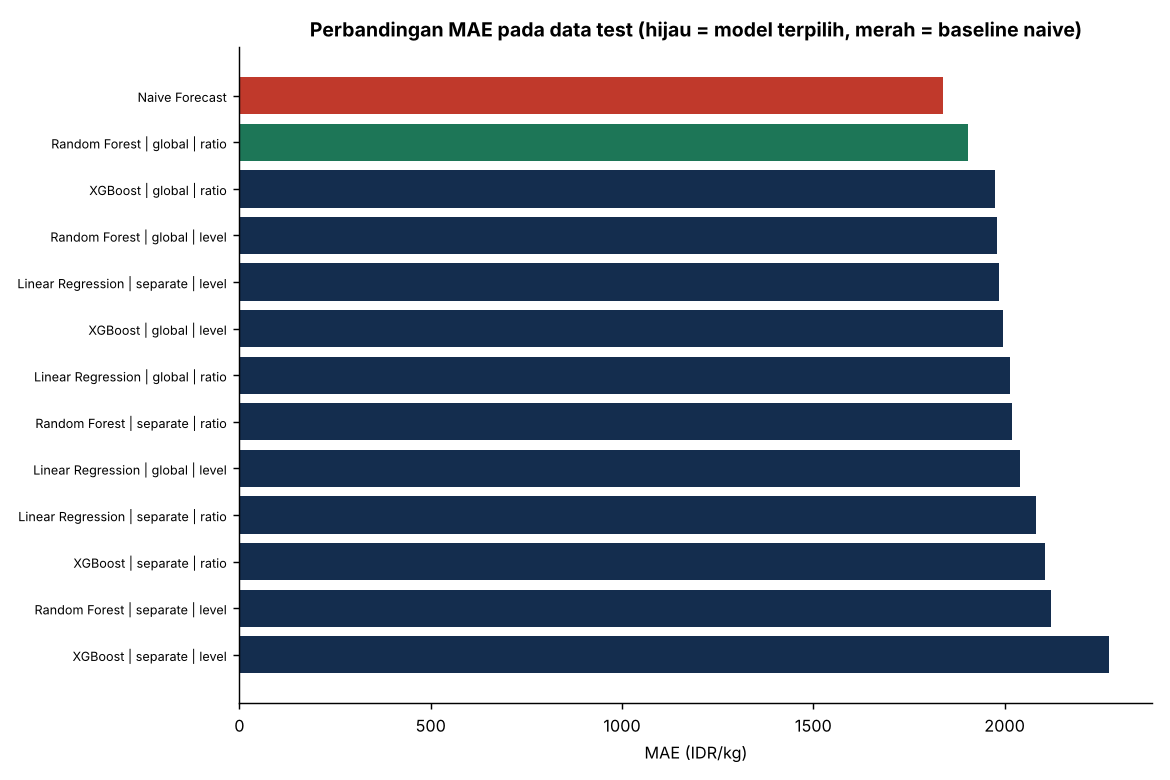

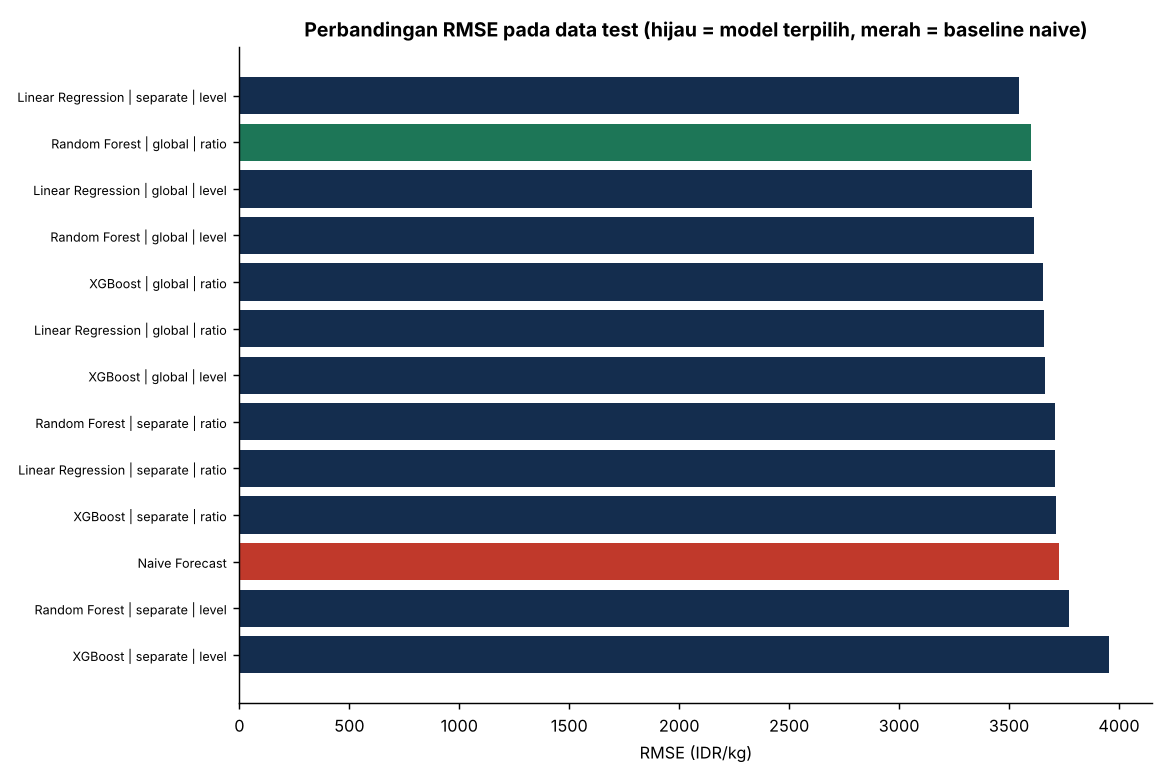

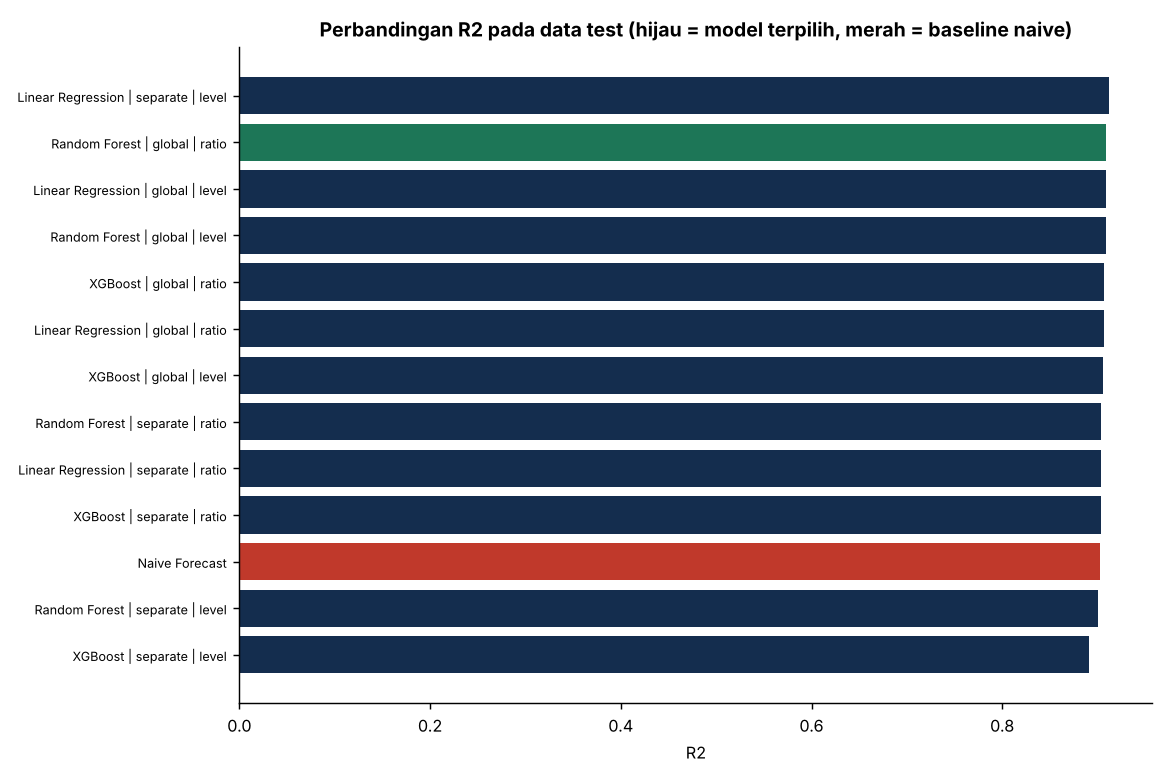

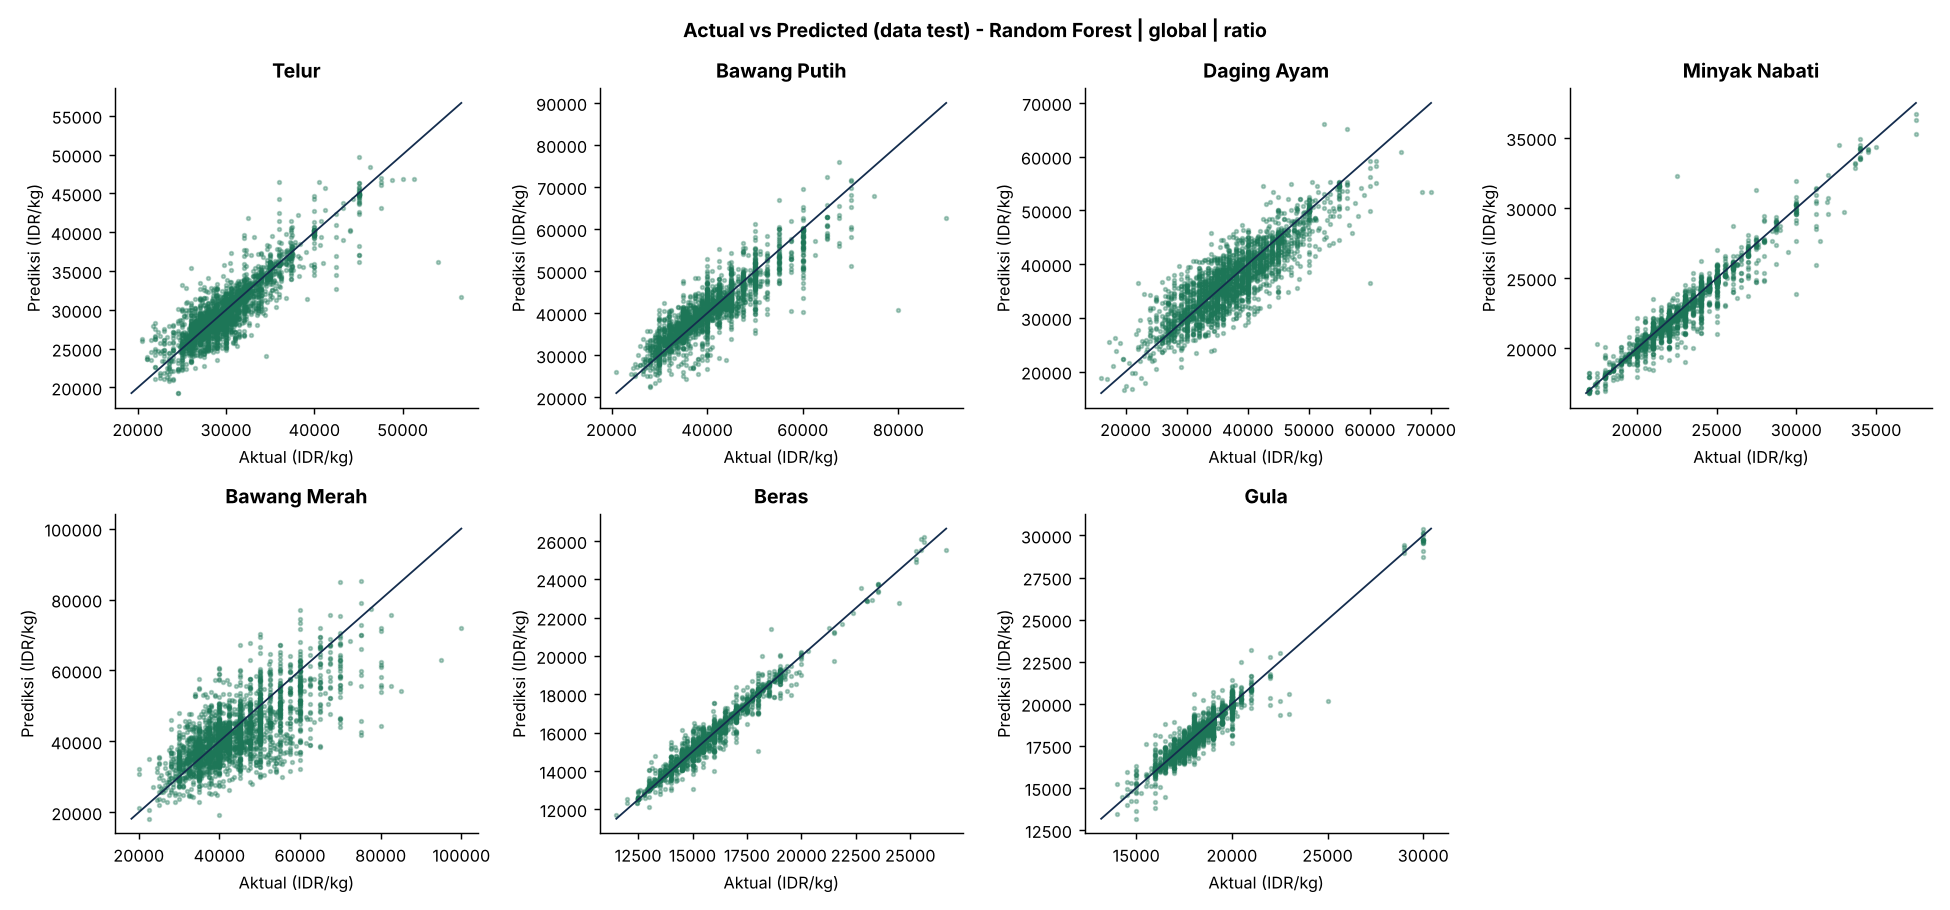

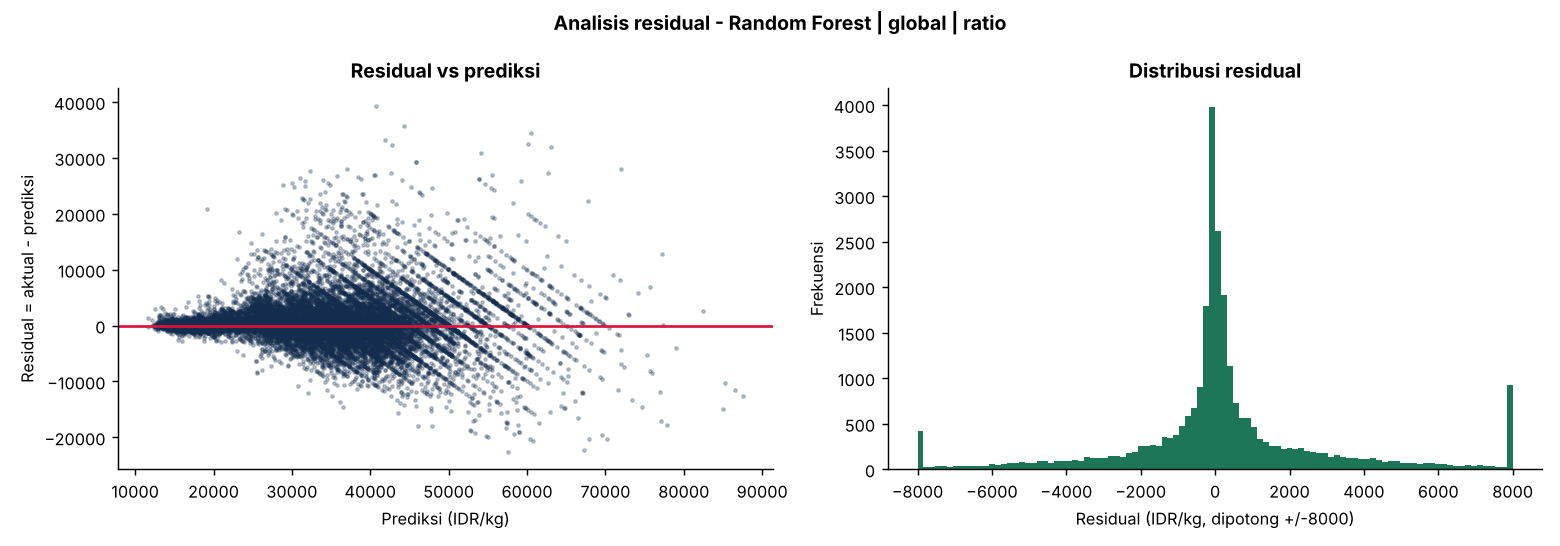

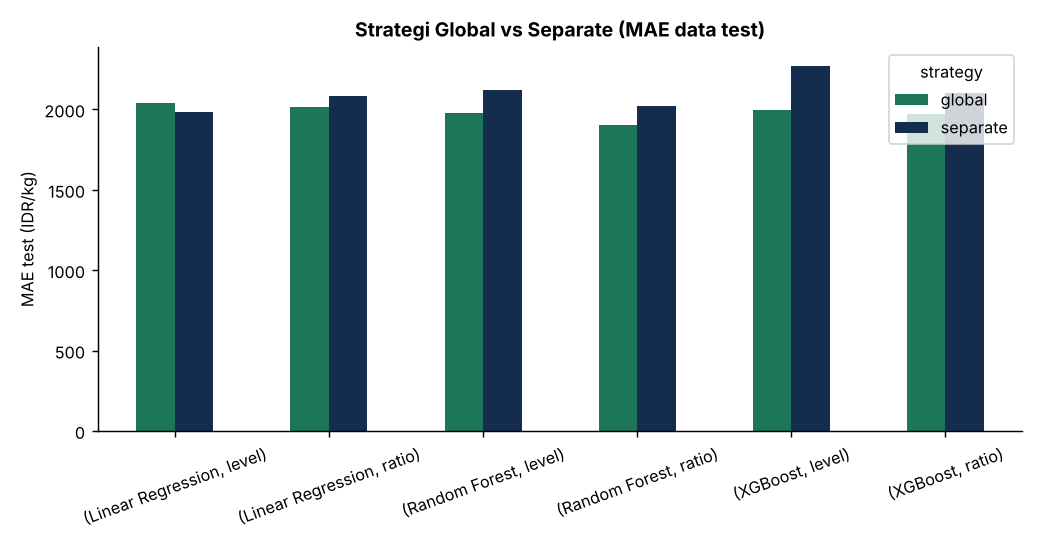

In [5]:
for f in sorted(Path('results/figures').glob('eval_*.png')):
    display(Image(str(f)))

In [6]:
# Verifikasi model tersimpan dapat dimuat dan konsisten dengan hasil evaluasi
from src.feature_engineering import build_features
from src.data_loader import load_long
from src import training as T
b = joblib.load('models/best_model.pkl')
_, _, test = T.make_splits(build_features(load_long()))
p = T.predict_strategy(b['models'], test, b['strategy'], b['target_mode'])
saved = pd.read_csv('results/prediction_results.csv')[meta['model_name']].values
print('Konsisten:', np.allclose(p, saved, atol=0.01), '| NaN:', np.isnan(p).sum())

Konsisten: True | NaN: 0
